# Deep Learning — Practical Exam (Set C)

Five mini-projects in one notebook:

| Step | Topic | Dataset |
|---|---|---|
| 1 | ANN — multi-class tabular classification | Wine Recognition (sklearn) |
| 2 | OpenCV — colour spaces, morphology, edges, face detection | 4 scikit-image images + 1 extra |
| 3 | CNN vs ANN — digit recognition | MNIST (Keras) |
| 4 | RNN (GRU) — time-series forecasting | Daily Minimum Temperatures, Melbourne |
| 5 | Transformers — fill-mask, question answering, text generation | 5 India-related paragraphs |
| 6 | Comparison, reflection | — |

In [39]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, Conv2D, MaxPooling2D, Flatten, GRU, LSTM
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

os.makedirs('outputs', exist_ok=True)


# Step 1: ANN — Artificial Neural Network
**Dataset:** Wine Recognition (178 wines, 13 chemical features, 3 cultivars)
**Task:** predict the wine cultivar from its chemical analysis.
**Expected output:** accuracy / loss plots, classification report, confusion matrix, saved `ann_wine_model.h5`.

## 1.1 Data Loading & Preprocessing

In [40]:
t1 = time.time()

from sklearn.datasets import load_wine
data = load_wine(as_frame=True)
df = data.frame

print(df.shape)

(178, 14)


In [41]:
print(df.head(5))


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [42]:
print(df.isnull().sum())

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [43]:
print(df.describe())

          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.9

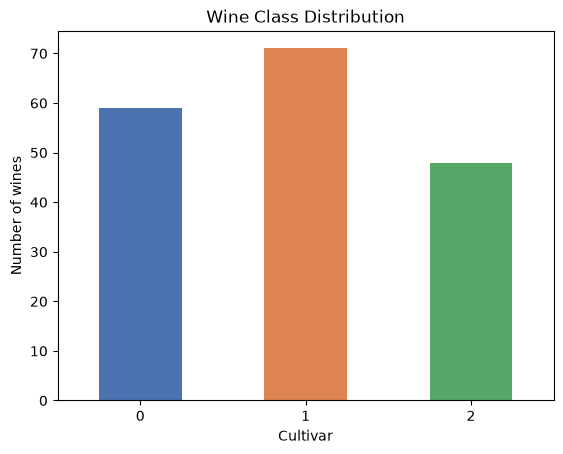

          proline       hue
min    278.000000  0.480000
max   1680.000000  1.710000
mean   746.893258  0.957449


In [3]:
# class distribution
df['target'].value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#dd8452', '#55a868'])
plt.title('Wine Class Distribution')
plt.xlabel('Cultivar')
plt.ylabel('Number of wines')
plt.xticks(rotation=0)
plt.show()

print(df[['proline', 'hue']].describe().loc[['min', 'max', 'mean']])

In [4]:
X = df.drop('target', axis=1)
y = df['target']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)    # fit on train only
X_test = scaler.transform(X_test)

y_train = to_categorical(y_train, num_classes=3)
y_test = to_categorical(y_test, num_classes=3)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(142, 13) (36, 13) (142, 3) (36, 3)


## 1.2 Build the ANN

In [5]:
model_ann = Sequential()
model_ann.add(Input(shape=(13,)))
model_ann.add(Dense(16, activation='relu'))
model_ann.add(Dense(8, activation='relu'))
model_ann.add(Dense(3, activation='softmax'))

model_ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

## 1.3 Train & Evaluate

In [6]:
history_ann = model_ann.fit(X_train, y_train, epochs=60, batch_size=8, validation_split=0.2, verbose=0)
print('final train acc:', round(history_ann.history['accuracy'][-1], 4), '| final val acc:', round(history_ann.history['val_accuracy'][-1], 4))

final train acc: 1.0 | final val acc: 1.0


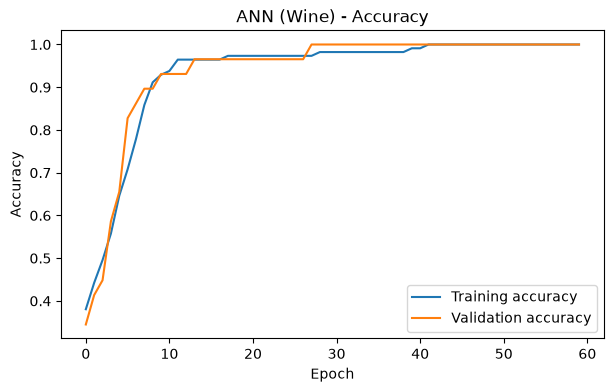

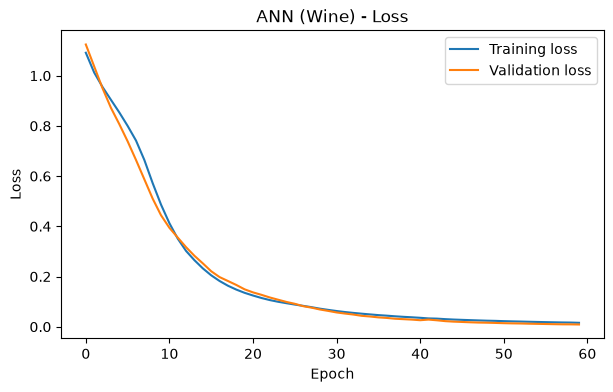

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(history_ann.history['accuracy'], label='Training accuracy')
plt.plot(history_ann.history['val_accuracy'], label='Validation accuracy')
plt.title('ANN (Wine) - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_ann.history['loss'], label='Training loss')
plt.plot(history_ann.history['val_loss'], label='Validation loss')
plt.title('ANN (Wine) - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Test Accuracy: 0.9722
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



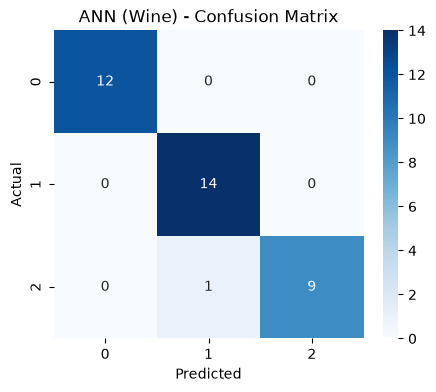

In [8]:
y_pred_prob = model_ann.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

ann_acc = accuracy_score(y_true, y_pred)
print('Test Accuracy:', round(ann_acc, 4))
print(classification_report(y_true, y_pred))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('ANN (Wine) - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 1.4 Save & Reflect

In [9]:
model_ann.save('ann_wine_model.h5')
time_ann = round((time.time() - t1) / 60, 1)
print('saved ann_wine_model.h5')

saved ann_wine_model.h5


# Step 2: OpenCV — Colour, Morphology & Face Detection
**Dataset:** 5 images — `astronaut`, `coffee`, `chelsea`, `rocket` from scikit-image + `colorwheel` (a brightly coloured image of my choice).
**Task:** colour-space conversion, colour masking, morphology, Sobel edges and Haar-cascade face detection (no training).

## 2.1 Load & Display

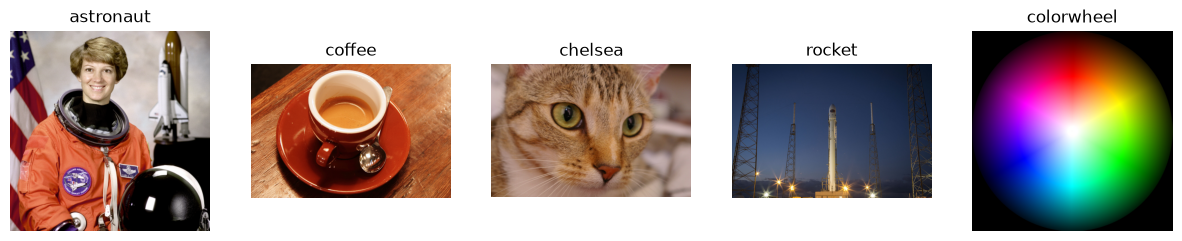

astronaut | shape: (512, 512, 3) | dtype: uint8 | min: 0 | max: 255 | mean brightness: 114.6
coffee | shape: (400, 600, 3) | dtype: uint8 | min: 0 | max: 255 | mean brightness: 98.62
chelsea | shape: (300, 451, 3) | dtype: uint8 | min: 0 | max: 231 | mean brightness: 115.31
rocket | shape: (427, 640, 3) | dtype: uint8 | min: 0 | max: 255 | mean brightness: 65.28
colorwheel | shape: (370, 371, 3) | dtype: uint8 | min: 0 | max: 255 | mean brightness: 76.33


In [10]:
t2 = time.time()

import cv2
from skimage import data

# skimage gives RGB, so convert to BGR to behave like cv2.imread()
names = ['astronaut', 'coffee', 'chelsea', 'rocket', 'colorwheel']
raw = [data.astronaut(), data.coffee(), data.chelsea(), data.rocket(), data.colorwheel()]

images = []
for img in raw:
    images.append(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

plt.figure(figsize=(15, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))    # BGR -> RGB for matplotlib
    plt.title(names[i])
    plt.axis('off')
plt.show()

for i in range(5):
    print(names[i], '| shape:', images[i].shape, '| dtype:', images[i].dtype, '| min:', images[i].min(), '| max:', images[i].max(), '| mean brightness:', round(images[i].mean(), 2))

## 2.2 Preprocessing Operations

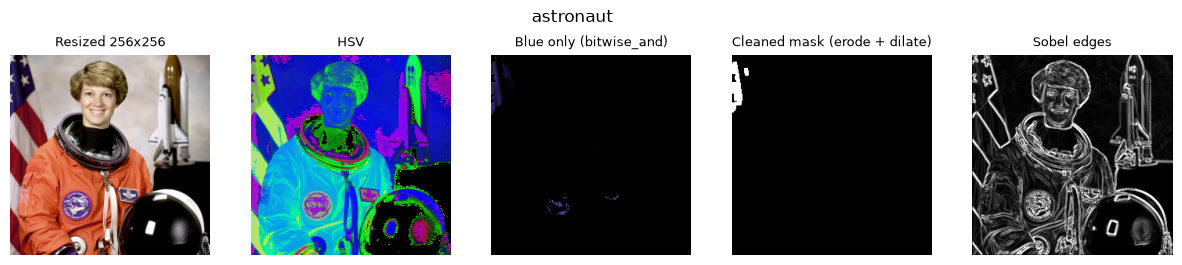

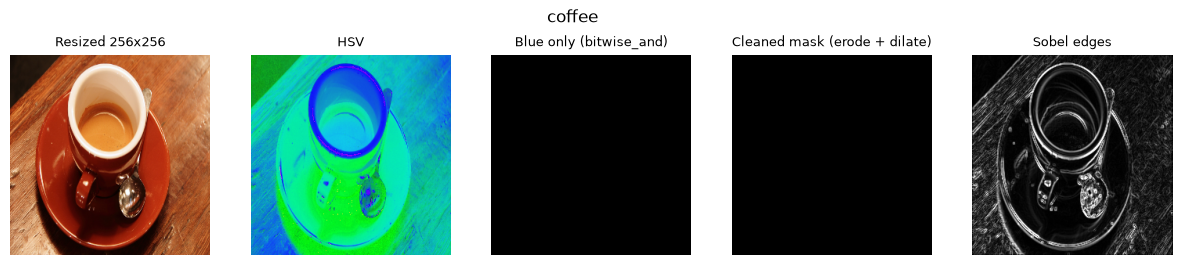

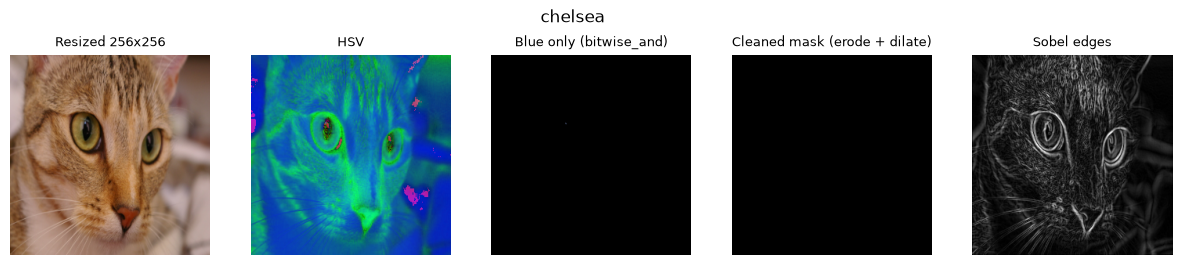

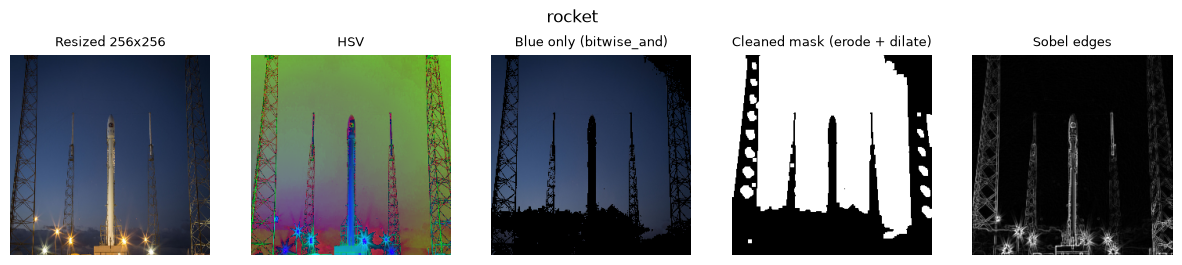

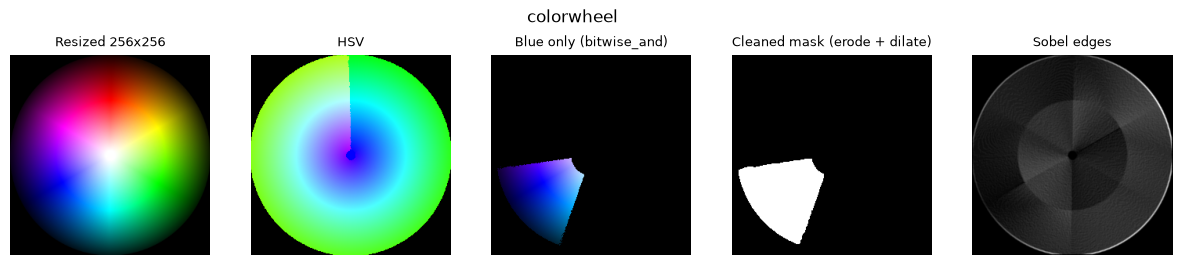

In [11]:
resized_list = []
hsv_list = []
masked_list = []
mask_list = []
clean_list = []
sobel_list = []

# blue range in OpenCV HSV (Hue goes from 0 to 179)
lower_blue = np.array([100, 80, 50])
upper_blue = np.array([130, 255, 255])
kernel = np.ones((5, 5), np.uint8)

for i in range(5):
    resized = cv2.resize(images[i], (256, 256))
    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)

    mask = cv2.inRange(hsv, lower_blue, upper_blue)
    masked = cv2.bitwise_and(resized, resized, mask=mask)

    clean = cv2.erode(mask, kernel)
    clean = cv2.dilate(clean, kernel)

    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel = cv2.addWeighted(cv2.convertScaleAbs(sobel_x), 0.5, cv2.convertScaleAbs(sobel_y), 0.5, 0)

    resized_list.append(resized)
    hsv_list.append(hsv)
    mask_list.append(mask)
    masked_list.append(masked)
    clean_list.append(clean)
    sobel_list.append(sobel)

    plt.figure(figsize=(15, 3))
    titles = ['Resized 256x256', 'HSV', 'Blue only (bitwise_and)', 'Cleaned mask (erode + dilate)', 'Sobel edges']
    pics = [cv2.cvtColor(resized, cv2.COLOR_BGR2RGB), hsv, cv2.cvtColor(masked, cv2.COLOR_BGR2RGB), clean, sobel]
    for j in range(5):
        plt.subplot(1, 5, j + 1)
        if j >= 3:
            plt.imshow(pics[j], cmap='gray')
        else:
            plt.imshow(pics[j])
        plt.title(titles[j], fontsize=9)
        plt.axis('off')
    plt.suptitle(names[i])
    plt.show()

## 2.3 Face Detection with Haar Cascade

In [12]:
# path of the downloaded xml file (keep it in the same folder as this notebook, or write the full path here)
cascade_path = 'haarcascade_frontalface_default.xml'

face_cascade = cv2.CascadeClassifier(cascade_path)
print('cascade loaded:', not face_cascade.empty())    # must print True

face_list = []
for i in range(5):
    gray = cv2.cvtColor(images[i], cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)

    out = images[i].copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 3)    # blue in BGR
        cv2.putText(out, 'Face', (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

    face_list.append(out)
    print(names[i], '-> faces found:', len(faces))

cascade loaded: True
astronaut -> faces found: 1
coffee -> faces found: 0
chelsea -> faces found: 0
rocket -> faces found: 0
colorwheel -> faces found: 0


In [13]:
# astronaut with different minNeighbors
gray = cv2.cvtColor(images[0], cv2.COLOR_BGR2GRAY)
for mn in [2, 5, 8]:
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=mn)
    print('astronaut | minNeighbors =', mn, '-> faces found:', len(faces))

astronaut | minNeighbors = 2 -> faces found: 1
astronaut | minNeighbors = 5 -> faces found: 1
astronaut | minNeighbors = 8 -> faces found: 1


## 2.4 Summary

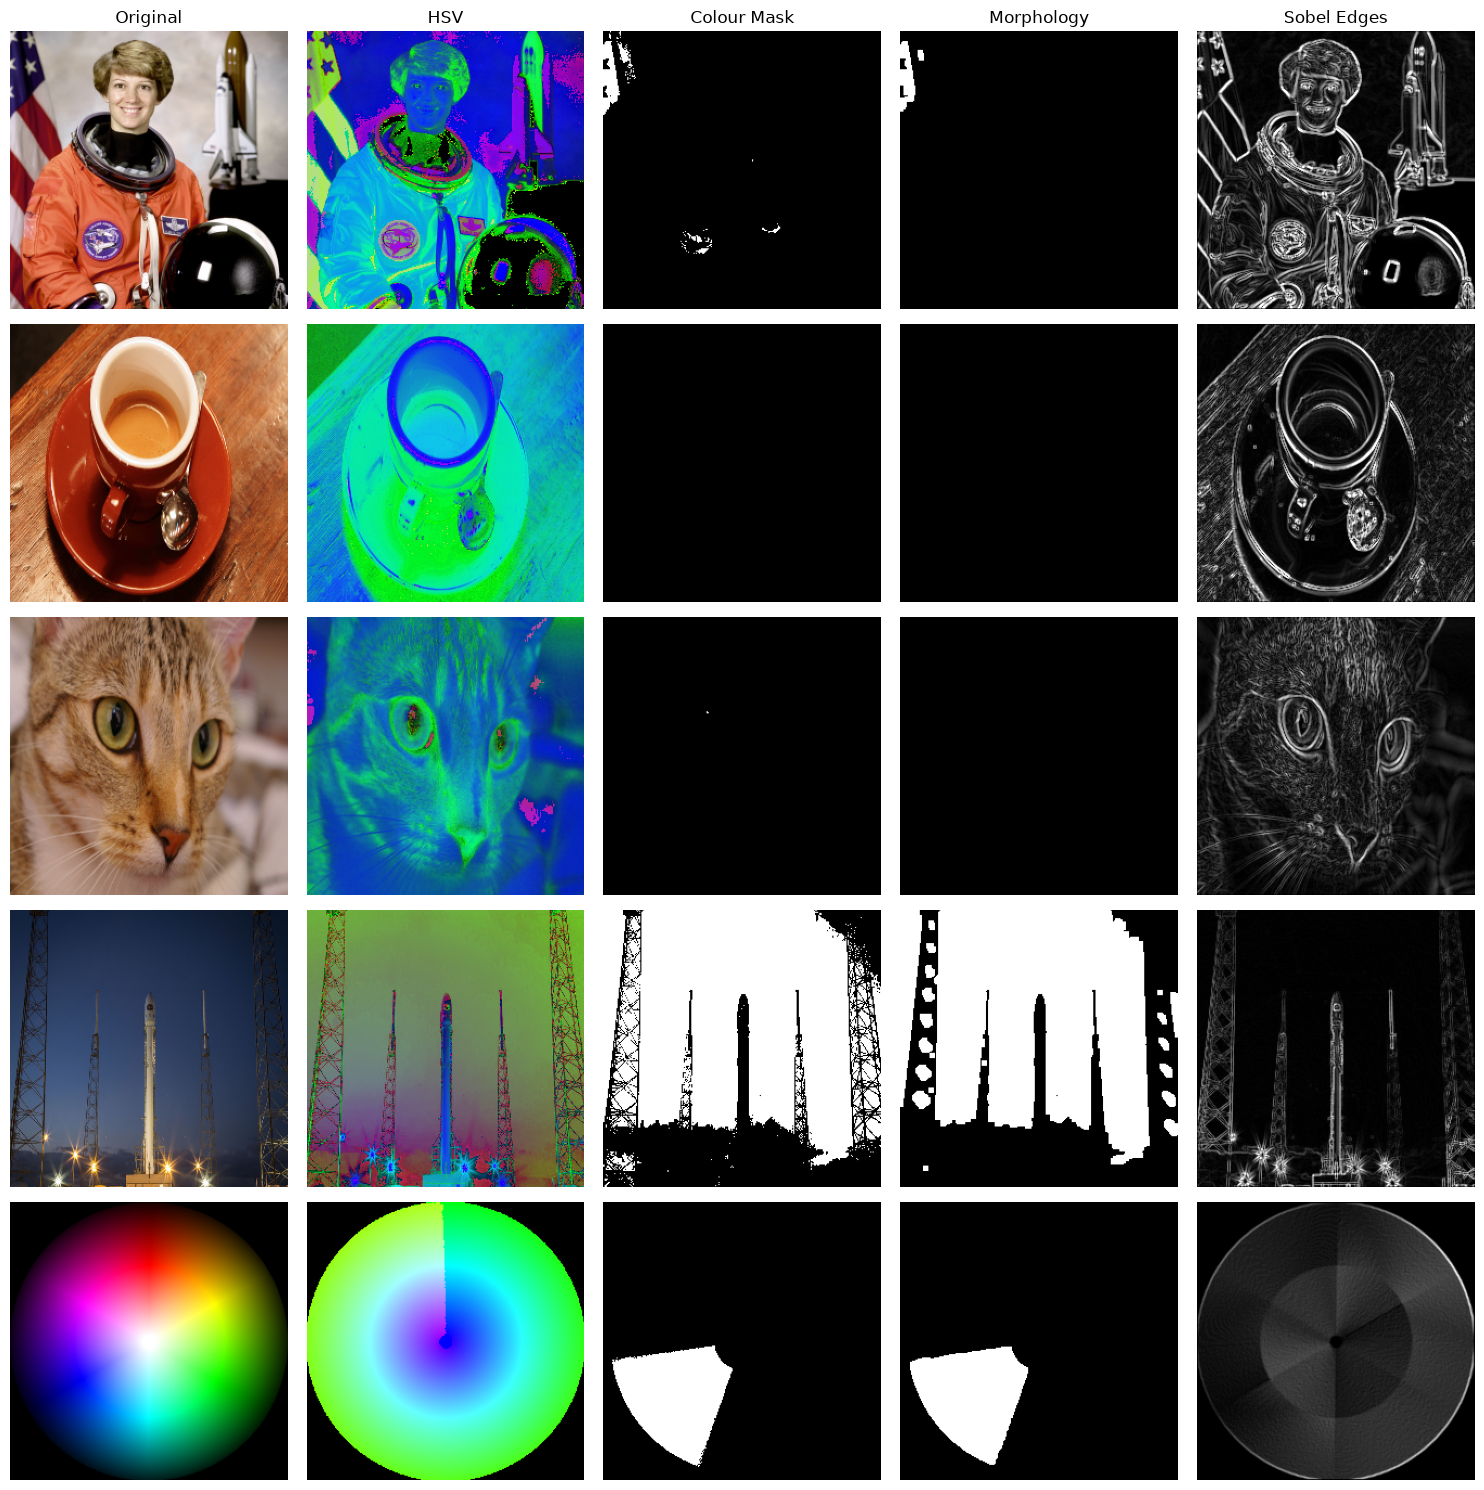

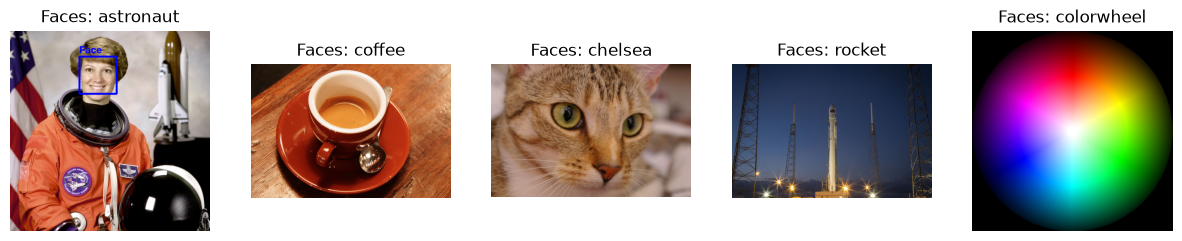

total faces detected (minNeighbors=5): 1


In [14]:
col_names = ['Original', 'HSV', 'Colour Mask', 'Morphology', 'Sobel Edges']

fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for i in range(5):
    axes[i][0].imshow(cv2.cvtColor(resized_list[i], cv2.COLOR_BGR2RGB))
    axes[i][1].imshow(hsv_list[i])
    axes[i][2].imshow(mask_list[i], cmap='gray')
    axes[i][3].imshow(clean_list[i], cmap='gray')
    axes[i][4].imshow(sobel_list[i], cmap='gray')
    for j in range(5):
        axes[i][j].axis('off')
        if i == 0:
            axes[i][j].set_title(col_names[j])
plt.tight_layout()
plt.savefig('outputs/opencv_5x5_grid.png')
plt.show()

plt.figure(figsize=(15, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.cvtColor(face_list[i], cv2.COLOR_BGR2RGB))
    plt.title('Faces: ' + names[i])
    plt.axis('off')
plt.savefig('outputs/opencv_face_detections.png')
plt.show()

# save every result with cv2.imwrite
for i in range(5):
    cv2.imwrite('outputs/' + names[i] + '_1_original.png', resized_list[i])
    cv2.imwrite('outputs/' + names[i] + '_2_hsv.png', hsv_list[i])
    cv2.imwrite('outputs/' + names[i] + '_3_colour_mask.png', masked_list[i])
    cv2.imwrite('outputs/' + names[i] + '_4_morphology.png', clean_list[i])
    cv2.imwrite('outputs/' + names[i] + '_5_sobel.png', sobel_list[i])
    cv2.imwrite('outputs/' + names[i] + '_6_faces.png', face_list[i])

total_faces = 0
for i in range(5):
    gray = cv2.cvtColor(images[i], cv2.COLOR_BGR2GRAY)
    total_faces = total_faces + len(face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5))
print('total faces detected (minNeighbors=5):', total_faces)
time_cv = round((time.time() - t2) / 60, 1)

# Step 3: CNN — Convolutional Neural Network
**Dataset:** MNIST handwritten digits (20,000 train / 4,000 test samples used).
**Task:** recognise digits with a CNN and compare it with a plain ANN baseline.

## 3.1 Data Loading & Preparation

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(20000, 28, 28, 1) (4000, 28, 28, 1) (20000, 10) (4000, 10)


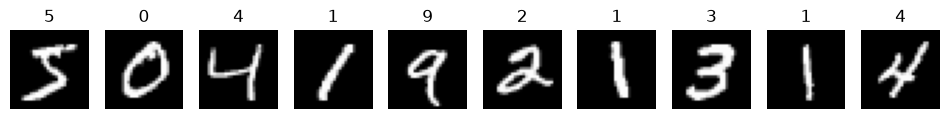

In [15]:
t3 = time.time()

from tensorflow.keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train[:20000]
y_train = y_train[:20000]
X_test = X_test[:4000]
y_test = y_test[:4000]

X_train = X_train / 255.0
X_test = X_test / 255.0
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

y_test_labels = y_test.copy()
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(np.argmax(y_train[i]))
    plt.axis('off')
plt.show()

## 3.2 Build the CNN and the ANN Baseline

In [19]:
model_cnn = Sequential()
model_cnn.add(Input(shape=(28, 28, 1)))
model_cnn.add(Conv2D(16, (3, 3), activation='relu'))
model_cnn.add(MaxPooling2D((2, 2)))
model_cnn.add(Conv2D(32, (3, 3), activation='relu'))
model_cnn.add(MaxPooling2D((2, 2)))
model_cnn.add(Flatten())
model_cnn.add(Dense(64, activation='relu'))
model_cnn.add(Dense(10, activation='softmax'))

model_ann_mnist = Sequential()
model_ann_mnist.add(Input(shape=(28, 28, 1)))
model_ann_mnist.add(Flatten())
model_ann_mnist.add(Dense(128, activation='relu'))
model_ann_mnist.add(Dense(64, activation='relu'))
model_ann_mnist.add(Dense(10, activation='softmax'))

model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_ann_mnist.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model_cnn.summary()
model_ann_mnist.summary()
print('CNN parameters:', model_cnn.count_params())
print('ANN parameters:', model_ann_mnist.count_params())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

CNN parameters: 56714
ANN parameters: 109386


## 3.3 Train & Evaluate

In [20]:
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history_cnn = model_cnn.fit(X_train, y_train, epochs=8, batch_size=64, validation_split=0.1, callbacks=[early_stop], verbose=1)
history_ann_mnist = model_ann_mnist.fit(X_train, y_train, epochs=8, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8683 - loss: 0.4574 - val_accuracy: 0.9630 - val_loss: 0.1394
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9639 - loss: 0.1205 - val_accuracy: 0.9730 - val_loss: 0.0877
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9763 - loss: 0.0773 - val_accuracy: 0.9790 - val_loss: 0.0618
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9836 - loss: 0.0573 - val_accuracy: 0.9770 - val_loss: 0.0688
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9857 - loss: 0.0470 - val_accuracy: 0.9840 - val_loss: 0.0579
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9885 - loss: 0.0366 - val_accuracy: 0.9855 - val_loss: 0.0502
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9899 - loss: 0.0318 - val_accuracy: 0.9850 - val_loss: 0.0469
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9923 - loss: 0.0234 - val_accuracy: 0.9830 - v

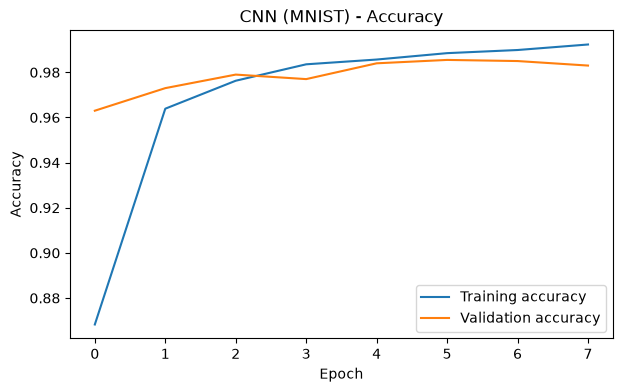

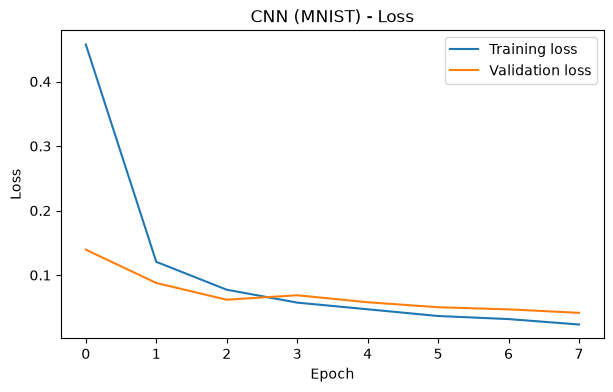

In [21]:
plt.figure(figsize=(7, 4))
plt.plot(history_cnn.history['accuracy'], label='Training accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation accuracy')
plt.title('CNN (MNIST) - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_cnn.history['loss'], label='Training loss')
plt.plot(history_cnn.history['val_loss'], label='Validation loss')
plt.title('CNN (MNIST) - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [22]:
cnn_loss, cnn_acc = model_cnn.evaluate(X_test, y_test, verbose=0)
ann_mnist_loss, ann_mnist_acc = model_ann_mnist.evaluate(X_test, y_test, verbose=0)

comparison = pd.DataFrame({
    'Model': ['CNN', 'ANN'],
    'Total Parameters': [model_cnn.count_params(), model_ann_mnist.count_params()],
    'Test Accuracy': [round(cnn_acc, 4), round(ann_mnist_acc, 4)]
})
print(comparison)

  Model  Total Parameters  Test Accuracy
0   CNN             56714         0.9793
1   ANN            109386         0.9575


              precision    recall  f1-score   support

           0       0.97      0.99      0.98       370
           1       0.98      0.99      0.99       450
           2       0.97      0.98      0.98       418
           3       0.97      0.99      0.98       408
           4       0.98      0.99      0.99       418
           5       0.99      0.97      0.98       372
           6       0.99      0.97      0.98       378
           7       0.98      0.97      0.98       411
           8       0.98      0.97      0.97       384
           9       0.98      0.97      0.98       391

    accuracy                           0.98      4000
   macro avg       0.98      0.98      0.98      4000
weighted avg       0.98      0.98      0.98      4000



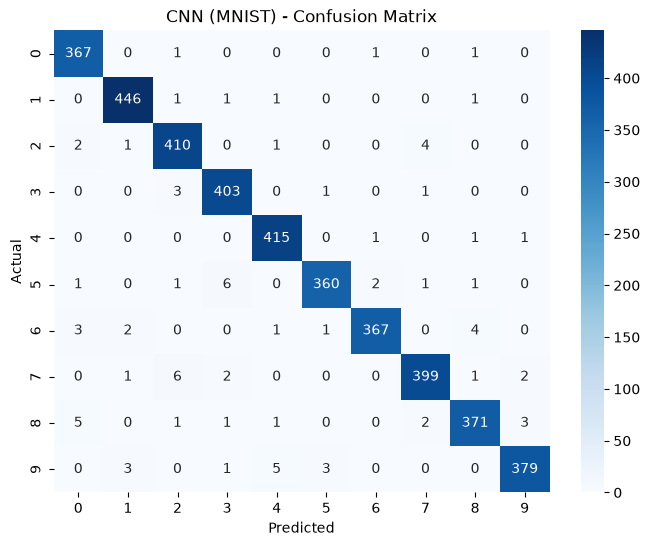

wrong predictions: 83


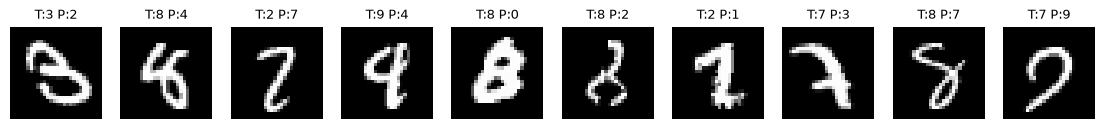

In [24]:
cnn_pred = np.argmax(model_cnn.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test_labels, cnn_pred))

cm = confusion_matrix(y_test_labels, cnn_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('CNN (MNIST) - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# wrongly predicted digits
wrong = np.where(cnn_pred != y_test_labels)[0]
print('wrong predictions:', len(wrong))

plt.figure(figsize=(14, 3))
for k in range(min(10, len(wrong))):
    idx = wrong[k]
    plt.subplot(1, 10, k + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title('T:' + str(y_test_labels[idx]) + ' P:' + str(cnn_pred[idx]), fontsize=9)
    plt.axis('off')
plt.show()

feature map shape: (1, 26, 26, 16)


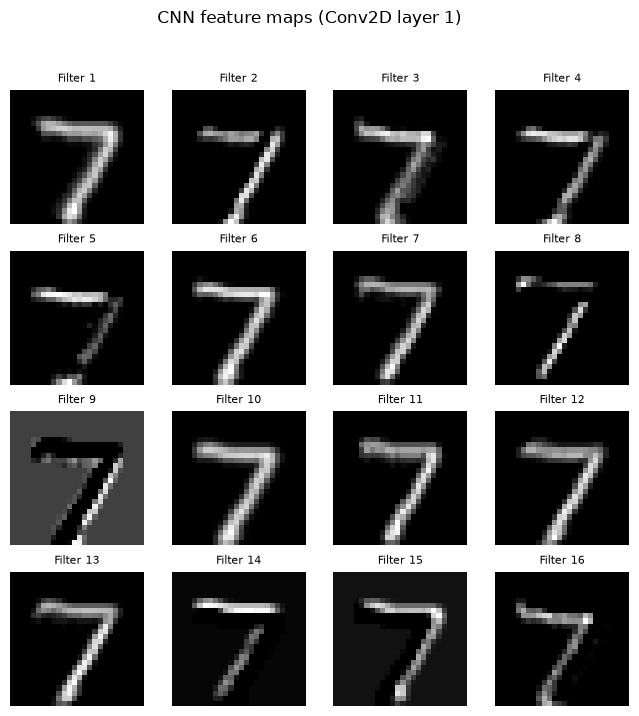

In [25]:
# feature maps of the first Conv2D layer
feature_model = Model(inputs=model_cnn.inputs, outputs=model_cnn.layers[0].output)
one_digit = X_test[0].reshape(1, 28, 28, 1)
maps = feature_model.predict(one_digit, verbose=0)
print('feature map shape:', maps.shape)

plt.figure(figsize=(8, 8))
for k in range(16):
    plt.subplot(4, 4, k + 1)
    plt.imshow(maps[0, :, :, k], cmap='gray')
    plt.title('Filter ' + str(k + 1), fontsize=8)
    plt.axis('off')
plt.suptitle('CNN feature maps (Conv2D layer 1)')
plt.show()

## 3.4 Save & Reflect

In [26]:
model_cnn.save('cnn_mnist_model.h5')
time_cnn = round((time.time() - t3) / 60, 1)
print('saved cnn_mnist_model.h5')

saved cnn_mnist_model.h5


# Step 4: RNN — GRU for Time-Series Forecasting
**Dataset:** Daily Minimum Temperatures in Melbourne (3,650 days, 1981–1990).
**Task:** predict tomorrow's minimum temperature from the previous 30 days.

## 4.1 Data Loading & Preparation

In [27]:
t4 = time.time()

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
df_temp = pd.read_csv(url, parse_dates=['Date'])

print(df_temp.head(5))
print(df_temp.dtypes)
print(df_temp.describe())

        Date  Temp
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8
3 1981-01-04  14.6
4 1981-01-05  15.8
Date    datetime64[us]
Temp           float64
dtype: object
                      Date         Temp
count                 3650  3650.000000
mean   1985-12-31 07:12:00    11.177753
min    1981-01-01 00:00:00     0.000000
25%    1983-07-02 06:00:00     8.300000
50%    1985-12-31 12:00:00    11.000000
75%    1988-06-30 18:00:00    14.000000
max    1990-12-31 00:00:00    26.300000
std                    NaN     4.071837


In [28]:
# make sure Temp is numeric
df_temp['Temp'] = pd.to_numeric(df_temp['Temp'], errors='coerce')
fixed = df_temp['Temp'].isnull().sum()
df_temp['Temp'] = df_temp['Temp'].interpolate()
print('values fixed with interpolate:', fixed)
print('missing after fixing:', df_temp['Temp'].isnull().sum())

values fixed with interpolate: 0
missing after fixing: 0


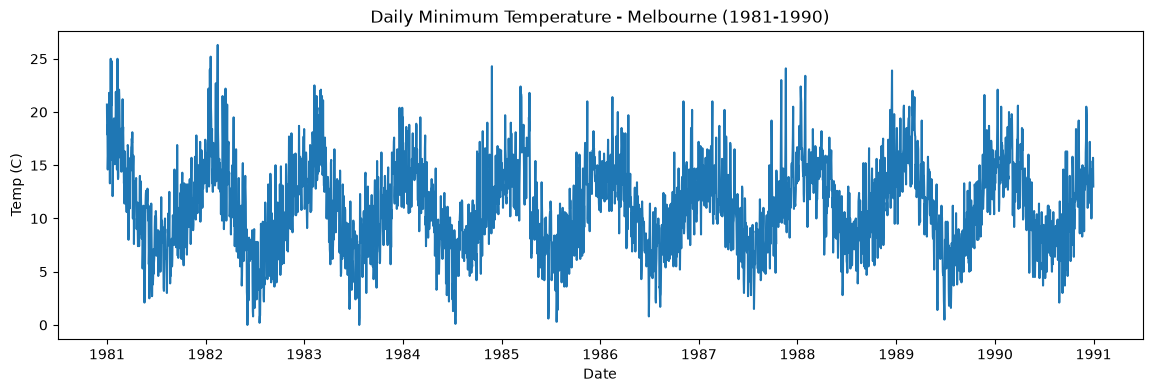

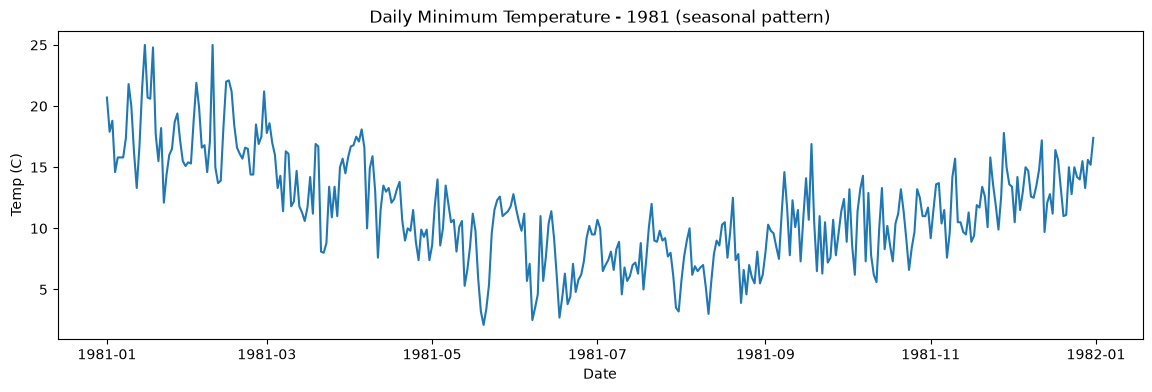

In [29]:
plt.figure(figsize=(14, 4))
plt.plot(df_temp['Date'], df_temp['Temp'])
plt.title('Daily Minimum Temperature - Melbourne (1981-1990)')
plt.xlabel('Date')
plt.ylabel('Temp (C)')
plt.show()

one_year = df_temp[df_temp['Date'].dt.year == 1981]
plt.figure(figsize=(14, 4))
plt.plot(one_year['Date'], one_year['Temp'])
plt.title('Daily Minimum Temperature - 1981 (seasonal pattern)')
plt.xlabel('Date')
plt.ylabel('Temp (C)')
plt.show()

In [30]:
values = df_temp['Temp'].values.reshape(-1, 1)

split_point = int(len(values) * 0.8)
train_part = values[:split_point]
test_part = values[split_point:]

from sklearn.preprocessing import MinMaxScaler
scaler_t = MinMaxScaler()
train_scaled = scaler_t.fit_transform(train_part)    # fit on train only
test_scaled = scaler_t.transform(test_part)

look_back = 30

X_train_t = []
y_train_t = []
for i in range(look_back, len(train_scaled)):
    X_train_t.append(train_scaled[i - look_back:i, 0])
    y_train_t.append(train_scaled[i, 0])

X_test_t = []
y_test_t = []
for i in range(look_back, len(test_scaled)):
    X_test_t.append(test_scaled[i - look_back:i, 0])
    y_test_t.append(test_scaled[i, 0])

X_train_t = np.array(X_train_t).reshape(-1, look_back, 1)
y_train_t = np.array(y_train_t)
X_test_t = np.array(X_test_t).reshape(-1, look_back, 1)
y_test_t = np.array(y_test_t)

print(X_train_t.shape, y_train_t.shape, X_test_t.shape, y_test_t.shape)

(2890, 30, 1) (2890,) (700, 30, 1) (700,)


## 4.2 Build the RNN and a Baseline

In [31]:
model_rnn = Sequential()
model_rnn.add(Input(shape=(30, 1)))
model_rnn.add(GRU(32, activation='tanh'))
model_rnn.add(Dense(1))

model_rnn.compile(optimizer='adam', loss='mse')
model_rnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# naive baseline: tomorrow = today
actual_c = scaler_t.inverse_transform(y_test_t.reshape(-1, 1)).flatten()
naive_c = scaler_t.inverse_transform(X_test_t[:, -1, :]).flatten()

naive_rmse = np.sqrt(np.mean((actual_c - naive_c) ** 2))
naive_mae = np.mean(np.abs(actual_c - naive_c))
print('Naive baseline RMSE (C):', round(naive_rmse, 3))

Naive baseline RMSE (C): 2.486


## 4.3 Train & Evaluate

Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0489 - val_loss: 0.0122
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0130 - val_loss: 0.0108
Epoch 3/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0111 - val_loss: 0.0102
Epoch 4/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0102 - val_loss: 0.0096
Epoch 5/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0096 - val_loss: 0.0093
Epoch 6/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0093 - val_loss: 0.0092
Epoch 7/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0093 - val_loss: 0.0091
Epoch 8/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0090 - val_loss: 0.0090
Epoch 9/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0090 - val_loss: 0.0091
Epoch 10/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0089 - val_loss: 0.0091
Epoch 11/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0089 - val_loss: 0.0093
Epoch 12/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0089 - val_lo

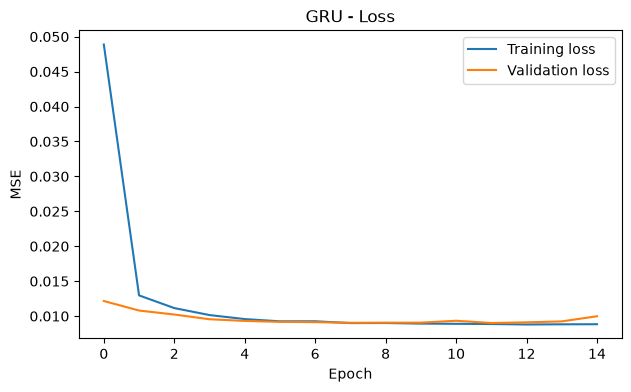

In [33]:
history_rnn = model_rnn.fit(X_train_t, y_train_t, epochs=15, batch_size=32, validation_split=0.1, verbose=1)

plt.figure(figsize=(7, 4))
plt.plot(history_rnn.history['loss'], label='Training loss')
plt.plot(history_rnn.history['val_loss'], label='Validation loss')
plt.title('GRU - Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

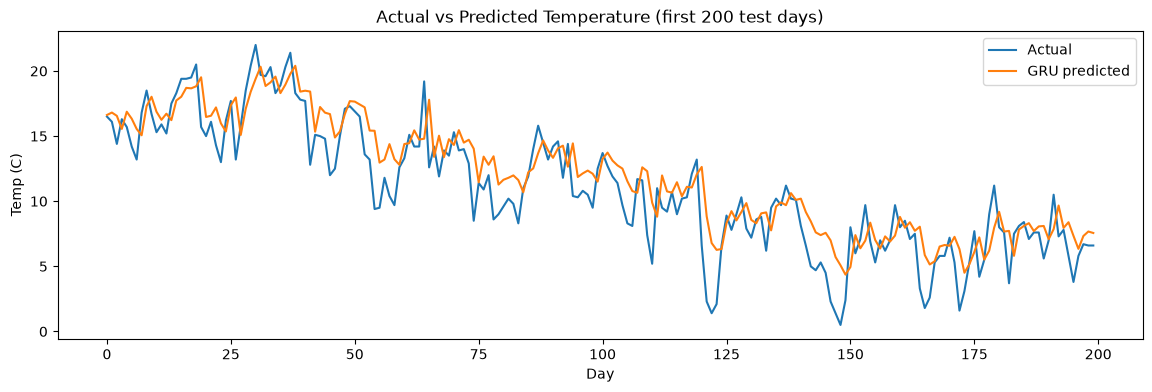

            Model  RMSE (C)  MAE (C)
0             GRU     2.356    1.859
1  Naive baseline     2.486    1.951


In [34]:
pred_scaled = model_rnn.predict(X_test_t, verbose=0)
pred_c = scaler_t.inverse_transform(pred_scaled).flatten()

plt.figure(figsize=(14, 4))
plt.plot(actual_c[:200], label='Actual')
plt.plot(pred_c[:200], label='GRU predicted')
plt.title('Actual vs Predicted Temperature (first 200 test days)')
plt.xlabel('Day')
plt.ylabel('Temp (C)')
plt.legend()
plt.show()

gru_rmse = np.sqrt(np.mean((actual_c - pred_c) ** 2))
gru_mae = np.mean(np.abs(actual_c - pred_c))

rnn_results = pd.DataFrame({
    'Model': ['GRU', 'Naive baseline'],
    'RMSE (C)': [round(gru_rmse, 3), round(naive_rmse, 3)],
    'MAE (C)': [round(gru_mae, 3), round(naive_mae, 3)]
})
print(rnn_results)

## 4.4 Save & Reflect

In [35]:
model_rnn.save('rnn_temperature_model.h5')
print('saved rnn_temperature_model.h5')

if gru_rmse < naive_rmse:
    print('The GRU BEAT the naive baseline by', round(naive_rmse - gru_rmse, 3), 'C RMSE')
else:
    print('The GRU did NOT beat the naive baseline (difference', round(gru_rmse - naive_rmse, 3), 'C RMSE)')

saved rnn_temperature_model.h5
The GRU BEAT the naive baseline by 0.13 C RMSE


In [36]:
# Bonus: LSTM(32) instead of GRU(32)
model_lstm = Sequential()
model_lstm.add(Input(shape=(30, 1)))
model_lstm.add(LSTM(32, activation='tanh'))
model_lstm.add(Dense(1))
model_lstm.compile(optimizer='adam', loss='mse')
model_lstm.fit(X_train_t, y_train_t, epochs=15, batch_size=32, validation_split=0.1, verbose=0)

lstm_pred = scaler_t.inverse_transform(model_lstm.predict(X_test_t, verbose=0)).flatten()
lstm_rmse = np.sqrt(np.mean((actual_c - lstm_pred) ** 2))
print('LSTM RMSE (C):', round(lstm_rmse, 3), '| GRU RMSE (C):', round(gru_rmse, 3))
time_rnn = round((time.time() - t4) / 60, 1)

LSTM RMSE (C): 2.335 | GRU RMSE (C): 2.356


# Step 6: Comparison, Reflection & Submission

## 6.1 Results Summary Table

In [38]:
summary = pd.DataFrame({
    'Step / Topic': ['ANN', 'OpenCV', 'CNN', 'RNN'],
    'Task type': ['Multi-class Classification', 'Preprocessing & Detection', 'Classification', 'Time-series Regression'],
    'Dataset used': ['Wine (178 rows, 13 features)', '5 images (4 skimage + colorwheel)', 'MNIST (20,000 train / 4,000 test)', 'Melbourne temperatures (3,650 days)'],
    'Key metric': ['Accuracy', 'N/A (faces detected)', 'Accuracy', 'RMSE (C)'],
    'Result achieved': [round(ann_acc, 4), str(total_faces) + ' faces', round(cnn_acc, 4), round(gru_rmse, 3)],
    'Time taken (min)': [time_ann, time_cv, time_cnn, time_rnn]
})
print(summary.to_string(index=False))
summary

Step / Topic                  Task type                        Dataset used           Key metric Result achieved  Time taken (min)
         ANN Multi-class Classification        Wine (178 rows, 13 features)             Accuracy          0.9722               0.6
      OpenCV  Preprocessing & Detection   5 images (4 skimage + colorwheel) N/A (faces detected)         1 faces               0.9
         CNN             Classification   MNIST (20,000 train / 4,000 test)             Accuracy          0.9793              15.4
         RNN     Time-series Regression Melbourne temperatures (3,650 days)             RMSE (C)           2.356               1.5


,Step / Topic,Task type,Dataset used,Key metric,Result achieved,Time taken (min)
0,ANN,Multi-class Classification,"Wine (178 rows, 13 features)",Accuracy,0.9722,0.6
1,OpenCV,Preprocessing & Detection,5 images (4 skimage + colorwheel),N/A (faces detected),1 faces,0.9
2,CNN,Classification,"MNIST (20,000 train / 4,000 test)",Accuracy,0.9793,15.4
3,RNN,Time-series Regression,"Melbourne temperatures (3,650 days)",RMSE (C),2.356,1.5
